In [2]:
import sys;sys.path.append('../')

In [3]:
import scipy.sparse as sp
import numpy as np
from matplotlib import pyplot as plt

from modules import Hamiltonian as ham
from modules import PauliStrings
from modules import Evolution as evol
from pathlib import Path

import importlib
importlib.reload(evol)

<module 'modules.Evolution' from '/home/luca/Documents/Sparse-QITE-via-LASSO/notebooks/../modules/Evolution.py'>

In [4]:
def fidelity_pure(psi,phi):
    '''
    input values should be column vectors
    '''
    F=np.abs(psi.conj().T@phi)**2
    return F[0,0]

def variance(psi,H):
    V=np.real((psi.conj().T@H@H@psi)-(psi.conj().T@H@psi)**2)
    return V[0,0]


In [20]:
# Compute sparsity as percentage of non-zero coefficients
def compute_sparsity_percentage(a_array):
    """
    Compute sparsity as percentage of non-zero coefficients
    100% means all coefficients are non-zero (dense)
    0% means all are zero (fully sparse)
    """
    n_steps = a_array.shape[0]
    sparsity = np.zeros(n_steps)
    
    for i in range(n_steps):
        # Flatten all coefficients at this time step
        coeffs = a_array[i, :, :].flatten()
        non_zero_count = np.count_nonzero(coeffs)
        total_count = coeffs.size
        sparsity[i] = 100 * non_zero_count / total_count
    
    return sparsity

#compute active support at final time step
def compute_active_support(a_array):
    """
    Compute active support
    """
    active_support = np.count_nonzero(a_array,axis=(1,2))
    return np.mean(active_support)

In [6]:
outputs_dir = Path('../outputs')
plots_dir = Path('../plots')

In [15]:
#Hamiltonian Params Traverse Field Ising model
n_qubits=8
J=0.5
h=1
T=2

#trotter params
H,H_trot=ham.TFIM(J,h,n_qubits,T=T)
print('Computing Eigs')
EH,VH = np.linalg.eigh(H.todense())
psigs=VH[:,0]
E_gs=EH[0]

#evolution parameters
dt=0.05
NQ=20 #maximum number of steps in QITE

#initial state
psi0np=np.zeros((2**n_qubits,1),dtype=complex)
psi0np[0]=1
psi_0=sp.csc_matrix(psi0np/np.linalg.norm(psi0np))


Computing Eigs


In [6]:
#QITE without Lasso
D=4
print("Computing QITE")
EQ_vanilla,psi_QITE_vanilla,a_vanilla = evol.QITE(n_qubits,H,H_trot,D,psi_0,NQ,dt)

Computing QITE


In [7]:
0.00045666616530707347

0.00045666616530707347

In [8]:
#QITE with vanilla Lasso
print("Computing QITE with vanilla Lasso")
EQ_lasso,psi_QITE_lasso,a_lasso = evol.QITE(n_qubits,H,H_trot,D,psi_0,NQ,dt,method='vanilla_lasso',lasso_lambda=0.001,lasso_max_iter=800,lasso_tol=1e-9)

Computing QITE with vanilla Lasso


In [9]:
#QITE with adaptive lambda
print("Computing QITE with adaptive lambda")
EQ_lasso_ada,psi_QITE_lasso_ada,a_lasso_ada = evol.QITE(n_qubits,H,H_trot,D,psi_0,NQ,dt,method='adaptive_lasso_v1',lasso_max_iter=800,lasso_tol=1e-9)

Computing QITE with adaptive lambda
Step 0, Lambda 0.40980981367615094: Objective function is within tolerance.
Step 0, Lambda 0.4296506051559629: Objective function is within tolerance.
Step 0, Lambda 0.42965508303766775: Objective function is within tolerance.
Step 0, Lambda 0.429655082736372: Objective function is within tolerance.
Step 0, Lambda 0.42965508273641495: Objective function is within tolerance.
Step 0, Lambda 0.42955873178893217: Objective function is within tolerance.
Step 1, Lambda 0.44874950065945796: Objective function is within tolerance.
Step 1, Lambda 0.4674157154186744: Objective function is within tolerance.
Step 1, Lambda 0.4674105595150504: Objective function is within tolerance.
Step 1, Lambda 0.46741056733350456: Objective function is within tolerance.
Step 1, Lambda 0.4674105884427464: Objective function is within tolerance.
Step 1, Lambda 0.4666955192536877: Objective function is within tolerance.
Step 2, Lambda 0.4831749230004876: Objective function is wi

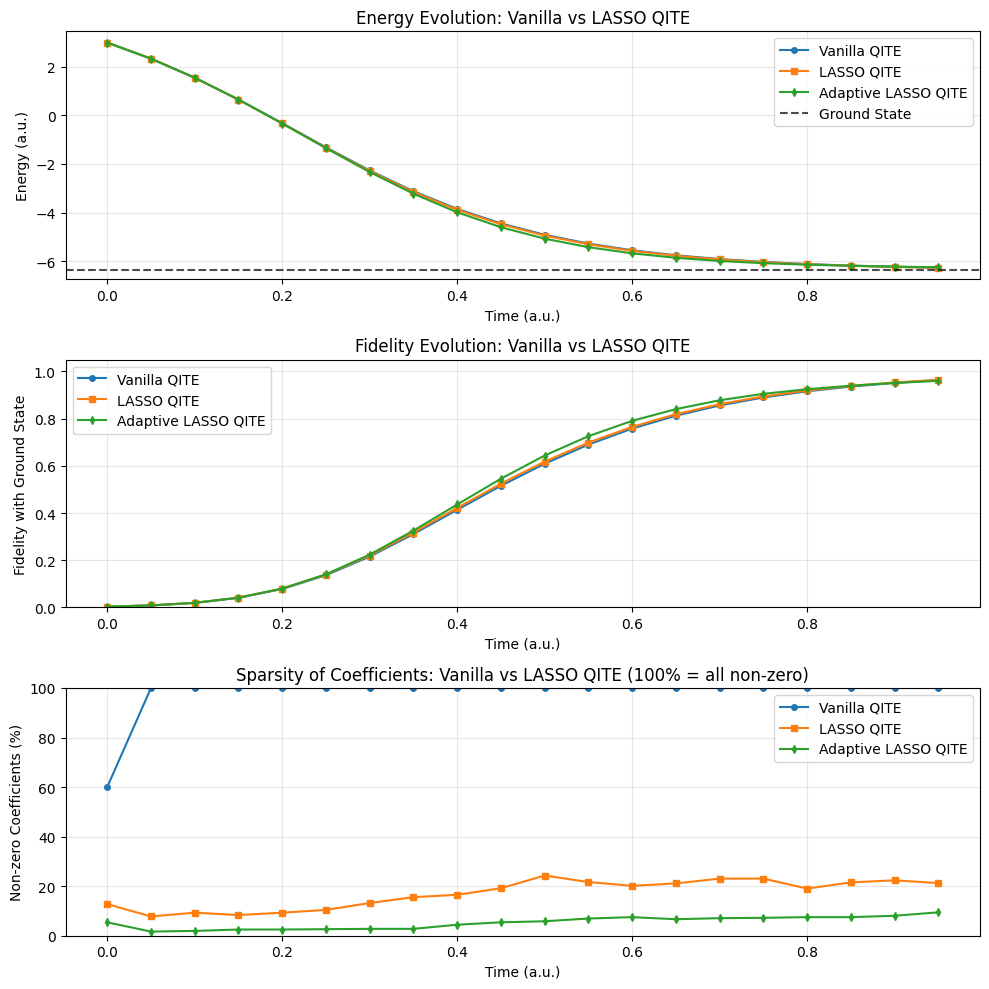

In [ ]:
# Compute fidelity with ground state for both methods
n_steps_vanilla = psi_QITE_vanilla.shape[1]
n_steps_lasso = psi_QITE_lasso.shape[1]
n_steps_lasso_ada = psi_QITE_lasso_ada.shape[1]

fidelity_vanilla = np.zeros(n_steps_vanilla)
fidelity_lasso = np.zeros(n_steps_lasso)
fidelity_lasso_ada = np.zeros(n_steps_lasso_ada)

psigs_col = psigs.reshape(-1, 1)  # Convert to column vector for fidelity computation

for i in range(n_steps_vanilla):
    psi_dense = psi_QITE_vanilla[:, i].toarray()
    fidelity_vanilla[i] = fidelity_pure(psi_dense, psigs_col)

for i in range(n_steps_lasso):
    psi_dense = psi_QITE_lasso[:, i].toarray()
    fidelity_lasso[i] = fidelity_pure(psi_dense, psigs_col)

for i in range(n_steps_lasso_ada):
    psi_dense = psi_QITE_lasso_ada[:, i].toarray()
    fidelity_lasso_ada[i] = fidelity_pure(psi_dense, psigs_col)

sparsity_vanilla = compute_sparsity_percentage(a_vanilla)
sparsity_lasso = compute_sparsity_percentage(a_lasso)
sparsity_lasso_ada = compute_sparsity_percentage(a_lasso_ada)


# Time arrays for plots (relative to start of each method)
t_vanilla = np.arange(n_steps_vanilla) * dt
t_lasso = np.arange(n_steps_lasso) * dt
t_lasso_ada = np.arange(n_steps_lasso_ada) * dt

# Create comparison plots
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# Energy comparison
axes[0].plot(t_vanilla, EQ_vanilla, 'o-', label='Vanilla QITE', markersize=4)
axes[0].plot(t_lasso, EQ_lasso, 's-', label='LASSO QITE', markersize=4)
axes[0].plot(t_lasso_ada, EQ_lasso_ada, 'd-', label='Adaptive LASSO QITE', markersize=4)
axes[0].axhline(y=E_gs, color='k', linestyle='--', label='Ground State', alpha=0.7)
axes[0].set_xlabel('Time (a.u.)')
axes[0].set_ylabel('Energy (a.u.)')
axes[0].set_title('Energy Evolution: Vanilla vs LASSO QITE')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Fidelity comparison
axes[1].plot(t_vanilla, fidelity_vanilla, 'o-', label='Vanilla QITE', markersize=4)
axes[1].plot(t_lasso, fidelity_lasso, 's-', label='LASSO QITE', markersize=4)
axes[1].plot(t_lasso_ada, fidelity_lasso_ada, 'd-', label='Adaptive LASSO QITE', markersize=4)
axes[1].set_xlabel('Time (a.u.)')
axes[1].set_ylabel('Fidelity with Ground State')
axes[1].set_title('Fidelity Evolution: Vanilla vs LASSO QITE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0, 1.05])

# Sparsity comparison (percentage of non-zero coefficients)
axes[2].plot(t_vanilla, sparsity_vanilla, 'o-', label='Vanilla QITE', markersize=4)
axes[2].plot(t_lasso, sparsity_lasso, 's-', label='LASSO QITE', markersize=4)
axes[2].plot(t_lasso_ada, sparsity_lasso_ada, 'd-', label='Adaptive LASSO QITE', markersize=4)
axes[2].set_xlabel('Time (a.u.)')
axes[2].set_ylabel('Non-zero Coefficients (%)')
axes[2].set_title('Sparsity of Coefficients: Vanilla vs LASSO QITE (100% = all non-zero)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].set_ylim([0, 100])

#plt.savefig(plots_dir / f'QITEVanilla_vs_LASSOQITE_vs_AdaptiveLASSOQITE.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

## Analysis with increasing D

In [7]:
import pickle
with open('results_QITE_D.pkl', 'rb') as f:
    results_QITE_D = pickle.load(f)

with open('results_AdaptiveLASSOQITE_D.pkl', 'rb') as f:
    results_AdaptiveLASSOQITE_D = pickle.load(f)

with open('results_LASSOQITE_D.pkl', 'rb') as f:
    results_LASSOQITE_D = pickle.load(f)

In [26]:
results_QITE_D[2]['Psi']

<List of Lists sparse matrix of dtype 'complex128'
	with 4865 stored elements and shape (256, 20)>

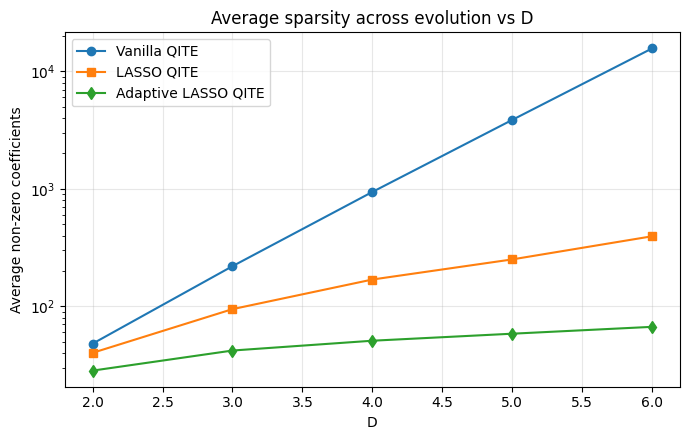

In [ ]:
# Plot D against average non-zero coefficients across evolution
common_D = sorted(
    set(results_QITE_D.keys()) & set(results_LASSOQITE_D.keys()) & set(results_AdaptiveLASSOQITE_D.keys())
)

avg_nnz_vanilla = [compute_active_support(results_QITE_D[D]['a']) for D in common_D]
avg_nnz_lasso = [compute_active_support(results_LASSOQITE_D[D]['a']) for D in common_D]
avg_nnz_lasso_ada = [compute_active_support(results_AdaptiveLASSOQITE_D[D]['a']) for D in common_D]

plt.figure(figsize=(7, 4.5))
plt.plot(common_D, avg_nnz_vanilla, 'o-', label='Vanilla QITE')
plt.plot(common_D, avg_nnz_lasso, 's-', label='LASSO QITE')
plt.plot(common_D, avg_nnz_lasso_ada, 'd-', label='Adaptive LASSO QITE')
plt.xlabel('D')
plt.ylabel('Average non-zero coefficients')
plt.title('Average sparsity across evolution vs D')
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()



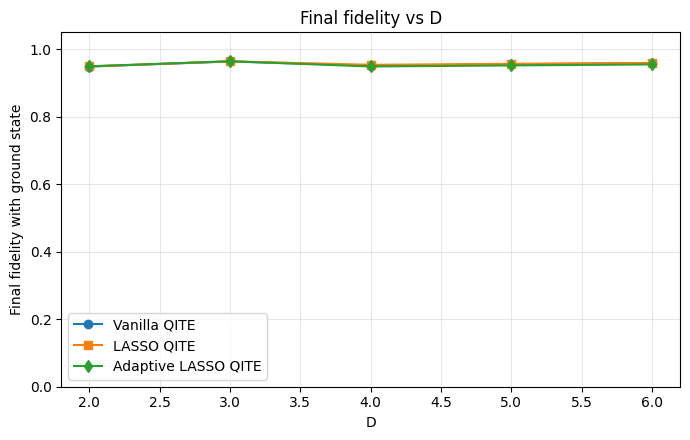

In [27]:
# Plot final-state fidelity against D for each method
psigs_col = psigs.reshape(-1, 1)

fidelity_vanilla = [fidelity_pure(results_QITE_D[D]['Psi'][:,-1].toarray(), psigs_col) for D in common_D]
fidelity_lasso = [fidelity_pure(results_LASSOQITE_D[D]['Psi'][:,-1].toarray(), psigs_col) for D in common_D]
fidelity_lasso_ada = [fidelity_pure(results_AdaptiveLASSOQITE_D[D]['Psi'][:,-1].toarray(), psigs_col) for D in common_D]

plt.figure(figsize=(7, 4.5))
plt.plot(common_D, fidelity_vanilla, 'o-', label='Vanilla QITE')
plt.plot(common_D, fidelity_lasso, 's-', label='LASSO QITE')
plt.plot(common_D, fidelity_lasso_ada, 'd-', label='Adaptive LASSO QITE')
plt.xlabel('D')
plt.ylabel('Final fidelity with ground state')
plt.title('Final fidelity vs D')
plt.grid(True, alpha=0.3)
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

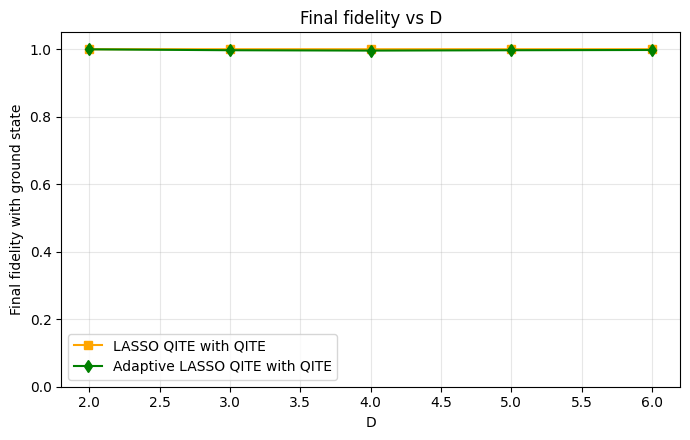

In [29]:
fidelity_lasso_with_qite = [fidelity_pure(results_LASSOQITE_D[D]['Psi'][:,-1].toarray(), results_QITE_D[D]['Psi'][:,-1].toarray()) for D in common_D]
fidelity_lasso_ada_with_qite = [fidelity_pure(results_AdaptiveLASSOQITE_D[D]['Psi'][:,-1].toarray(), results_QITE_D[D]['Psi'][:,-1].toarray()) for D in common_D]

plt.figure(figsize=(7, 4.5))
plt.plot(common_D, fidelity_lasso_with_qite, 's-',color='orange', label='LASSO QITE with QITE')
plt.plot(common_D, fidelity_lasso_ada_with_qite, 'd-', color='green', label='Adaptive LASSO QITE with QITE')
plt.xlabel('D')
plt.ylabel('Final fidelity with ground state')
plt.title('Final fidelity vs D')
plt.grid(True, alpha=0.3)
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

## Weight distribution color map

Max row-sum deviation from 1 (vanilla): 2.220446049250313e-16
Max row-sum deviation from 1 (lasso): 2.220446049250313e-16
Max row-sum deviation from 1 (adaptive lasso): 1.1102230246251565e-16


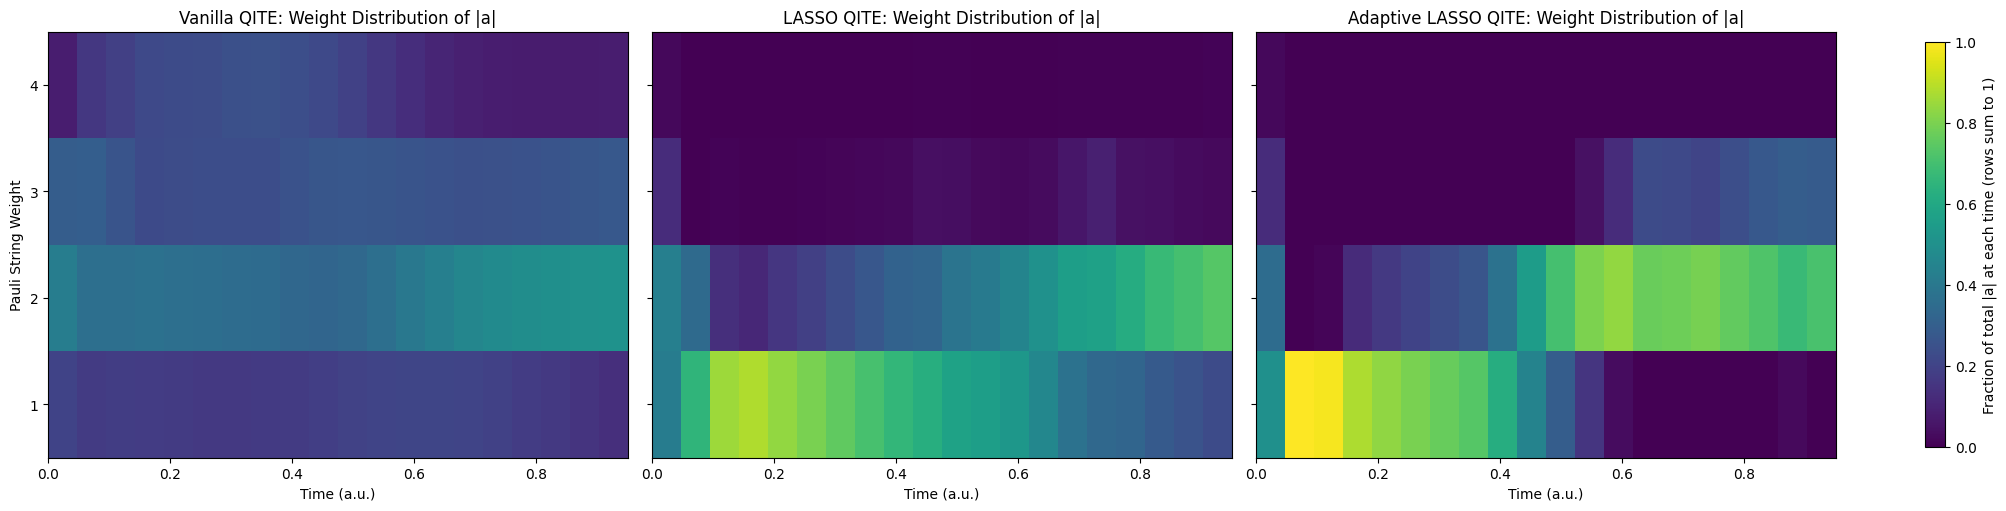

In [11]:
# Weight-resolved distribution of QITE coefficients over time (color plots)
# We aggregate coefficients by Pauli-string weight (number of non-identity letters)

# Reconstruct the Pauli-string labels used in QITE so each coefficient index maps to a weight
if np.isreal(H.data).all() and np.isreal(psi_0.data).all():
    _, PD_strings, _ = PauliStrings.real(H_trot, D, n_qubits, PDstr=True)
else:
    _, PD_strings, _ = PauliStrings.general(H_trot, D, n_qubits, PDstr=True)

# Weight for each Pauli index j (same ordering for all trotter pieces)
weights_per_j = np.array([sum(ch != 'I' for ch in pstr) for pstr in PD_strings[0]], dtype=int)
unique_weights = np.arange(weights_per_j.min(), weights_per_j.max() + 1)


def weight_distribution_over_time(a_array, weights_j, weight_values, normalize=True):
    """
    Build matrix M[t, w] = aggregated |a| at time t for Pauli weight w.
    If normalize=True, each time row is normalized to sum to 1.
    """
    n_steps = a_array.shape[0]
    M = np.zeros((n_steps, len(weight_values)), dtype=float)

    for t_idx in range(n_steps):
        coeffs = np.abs(a_array[t_idx, :, :])  # shape: (Nk, num_paulis)
        for w_idx, w in enumerate(weight_values):
            mask = (weights_j == w)
            if np.any(mask):
                M[t_idx, w_idx] = coeffs[:, mask].sum()

        if normalize:
            row_sum = M[t_idx].sum()
            if row_sum > 0:
                M[t_idx] /= row_sum

    return M

M_vanilla = weight_distribution_over_time(a_vanilla, weights_per_j, unique_weights, normalize=True)
M_lasso = weight_distribution_over_time(a_lasso, weights_per_j, unique_weights, normalize=True)
M_lasso_ada = weight_distribution_over_time(a_lasso_ada, weights_per_j, unique_weights, normalize=True)

# Sanity check: each time slice should sum to 1 after normalization
print('Max row-sum deviation from 1 (vanilla):', np.max(np.abs(M_vanilla.sum(axis=1) - 1.0)))
print('Max row-sum deviation from 1 (lasso):', np.max(np.abs(M_lasso.sum(axis=1) - 1.0)))
print('Max row-sum deviation from 1 (adaptive lasso):', np.max(np.abs(M_lasso_ada.sum(axis=1) - 1.0)))

# Use physical time axes matching each method's available steps
t_vanilla_w = np.arange(M_vanilla.shape[0]) * dt
t_lasso_w = np.arange(M_lasso.shape[0]) * dt
t_lasso_ada_w = np.arange(M_lasso_ada.shape[0]) * dt

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True, constrained_layout=True)

# Heatmap for vanilla
im0 = axes[0].imshow(
    M_vanilla.T,
    origin='lower',
    aspect='auto',
    extent=[t_vanilla_w[0], t_vanilla_w[-1] if len(t_vanilla_w) > 1 else t_vanilla_w[0] + dt,
            unique_weights[0] - 0.5, unique_weights[-1] + 0.5],
    cmap='viridis',
    vmin=0.0,
    vmax=1.0
)
axes[0].set_title('Vanilla QITE: Weight Distribution of |a|')
axes[0].set_xlabel('Time (a.u.)')
axes[0].set_ylabel('Pauli String Weight')
axes[0].set_yticks(unique_weights)

# Heatmap for lasso
im1 = axes[1].imshow(
    M_lasso.T,
    origin='lower',
    aspect='auto',
    extent=[t_lasso_w[0], t_lasso_w[-1] if len(t_lasso_w) > 1 else t_lasso_w[0] + dt,
            unique_weights[0] - 0.5, unique_weights[-1] + 0.5],
    cmap='viridis',
    vmin=0.0,
    vmax=1.0
)
axes[1].set_title('LASSO QITE: Weight Distribution of |a|')
axes[1].set_xlabel('Time (a.u.)')
axes[1].set_yticks(unique_weights)

# Heatmap for adaptive lasso
im2 = axes[2].imshow(
    M_lasso_ada.T,
    origin='lower',
    aspect='auto',
    extent=[t_lasso_ada_w[0], t_lasso_ada_w[-1] if len(t_lasso_ada_w) > 1 else t_lasso_ada_w[0] + dt,
            unique_weights[0] - 0.5, unique_weights[-1] + 0.5],
    cmap='viridis',
    vmin=0.0,
    vmax=1.0
)
axes[2].set_title('Adaptive LASSO QITE: Weight Distribution of |a|')
axes[2].set_xlabel('Time (a.u.)')
axes[2].set_yticks(unique_weights)

# Shared colorbar: fraction of total |a| at each time step
cbar = fig.colorbar(im2, ax=axes.ravel().tolist(), shrink=0.95)
cbar.set_label('Fraction of total |a| at each time (rows sum to 1)')

plt.savefig(plots_dir / 'QITE_weight_distribution_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()